# V-JEPA

A moving disk is divided into non-overlapping 2-frame tubelets of 4×4 pixels. The target is a contextual feature vector for each hidden tubelet.

In [1]:
from pathlib import Path
import sys

start = Path.cwd()
for parent in (start, *start.parents):
    if (parent / "gallery" / "__init__.py").is_file():
        sys.path.insert(0, str(parent))
        break
else:
    raise RuntimeError("Open this example inside the Representation Learning folder.")

## Tokenise the input

Tokens keep a fixed spatial order. Context and target positions are selected after tokenisation.

In [2]:
import copy
import matplotlib.pyplot as plt
import torch
from torch import nn
from gallery.vision import digits_split
from gallery.neural import seed_cpu
from gallery.representations import probe_encoders, update_teacher

from gallery.vision import moving_clips
from gallery.representations import PatchEncoder, MaskPredictor, train_masked, mask_test


def patchify(tensor):
    return tensor.reshape(-1, 3, 2, 4, 4, 4, 4).permute(0, 1, 3, 5, 2, 4, 6).reshape(-1, 48, 32)

## Predict hidden features

A full-view, stop-gradient target encoder supplies the targets. The online encoder sees visible tokens only. A separate predictor combines the context with learned mask tokens and positional embeddings.

In [3]:
seed_cpu()
train, y = moving_clips(576, 17)
test, y_test = moving_clips(160, 79)
X = patchify(torch.tensor(train))
T = patchify(torch.tensor(test))
encoder = PatchEncoder(X.shape[2], X.shape[1])
initial = copy.deepcopy(encoder)
predictor = MaskPredictor(X.shape[1])
teacher, history = train_masked(encoder, predictor, X, times=3, epochs=14)
mask_test(encoder, predictor, teacher, T, times=3)

Held-out masked latent MAE: 0.1960


## Probe a frozen encoder

A logistic probe is trained on the labelled training partition after self-supervision. The raw and random-feature baselines see the same examples.

Raw input: accuracy 0.362 | balanced accuracy 0.362 | macro F1 0.359
Random encoder: accuracy 0.300 | balanced accuracy 0.300 | macro F1 0.299


Trained encoder: accuracy 0.338 | balanced accuracy 0.337 | macro F1 0.335
Held-out mean feature SD: 0.1713 | Effective covariance rank: 100.59


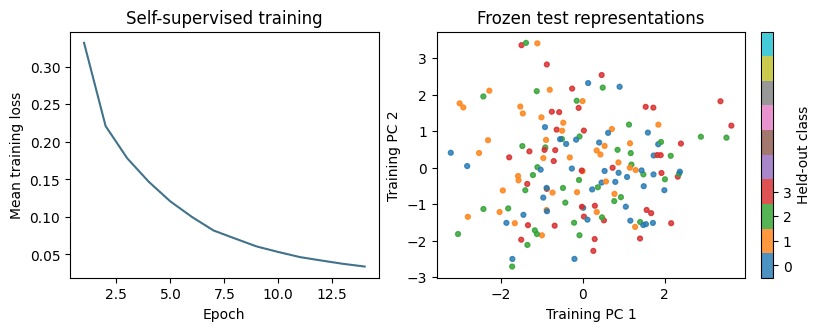

In [4]:
probe_encoders(initial, encoder, X, T, y, y_test, history)
plt.show()

## Reading the result

This CPU-scale adaptation uses one transformer layer and two disjoint block masks. The paper studies much larger inputs and training sets. Its benchmark results are a separate experiment.

## References

[Bardes et al., Revisiting Feature Prediction for Learning Visual Representations from Video (2024)](https://arxiv.org/abs/2404.08471)

[Frozen probes and masked-prediction training](../gallery/representations.py)